# LT05 — Two-by-two customer segmentation (Olist)

**Question.** Which customers should get which level of investment?

**Method (stated before results).**
- Axis 1, predicted CLV: BG/NBD expected purchases × Gamma-Gamma expected order value over the next 6 months,
  fitted on 2017 only.
- Axis 2, churn proxy: `1 - P(alive)` from BG/NBD at the end of 2017. This stands in for the CH02 churn model,
  which is not in this portfolio (the plan allowed CH02 "if available").
- Each axis is cut at its median. That gives four segments.
- Check: each segment's realised 2018 H1 revenue and purchase rate, which the models never saw.

**Data.** Olist Brazilian E-Commerce, delivered orders, revenue = item price. Customers are `customer_unique_id`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from value_segments.data import load_olist, make_windows, split_windows
from value_segments.segments import (
    assign_segments,
    fit_models,
    predict_alive,
    predict_clv,
    segment_profile,
)

DATA_DIR = Path(os.environ.get("CLV_DATA_PATH", Path.home() / ".local/share/clv-data/olist"))
REPORTS = Path("../reports")
FIGS = REPORTS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

## 1. Windows

Same cut as LT03: observation 2017-01-01 to 2018-01-01, holdout 2018-01-01 to 2018-07-01.

In [2]:
txns = load_olist(DATA_DIR)
w = make_windows("2017-01-01", t_obs_months=12, t_hold_months=6)
obs, hold = split_windows(txns, w)
hold_days = int((w.hold_end - w.obs_end).days)
print(f"obs customers: {obs['customer_id'].nunique():,}; holdout customers: {hold['customer_id'].nunique():,}")

obs customers: 42,136; holdout customers: 39,413


## 2. Fit and score

Only customers who bought in 2017 are segmented, because only they have a fitted history.

In [3]:
models = fit_models(obs, w.obs_end)
customers = models.summary.index
scores = pd.DataFrame(
    {
        "pred_clv": predict_clv(models, customers, horizon_days=hold_days),
        "p_alive": predict_alive(models, customers),
    },
    index=customers,
)
print(scores.describe().round(3))

        pred_clv    p_alive
count  42136.000  42136.000
mean       1.784      0.985
std        2.340      0.116
min        0.639      0.024
25%        1.094      1.000
50%        1.509      1.000
75%        2.251      1.000
max      166.064      1.000


## 3. Segments

Medians are computed on the 2017 customers. Ties at the median go to the lower group.

In [4]:
seg = assign_segments(scores)
holdout_revenue = hold.groupby("customer_id")["revenue"].sum()
profile = segment_profile(seg, holdout_revenue)
print(f"CLV median: {seg.attrs['clv_median']:.2f}; churn-proxy median: {seg.attrs['churn_median']:.3f}")
profile.round(3)

CLV median: 1.51; churn-proxy median: 0.000


,segment,customers,share_of_customers,mean_pred_clv,mean_p_alive,mean_holdout_revenue,share_bought_in_holdout,share_of_holdout_revenue
0,Stars,20380,0.484,2.210,1.000,1.609,0.013,0.459
1,Loyal at risk,664,0.016,10.002,0.105,10.832,0.063,0.101
2,Growth,21046,0.499,1.114,1.000,1.492,0.011,0.440
3,"Low value, lapsing",46,0.001,1.120,0.036,0.000,0.000,0.000


## 4. Does each axis carry signal?

Two checks, both on the 2018 H1 holdout that the models never saw:
- Rank correlation of predicted CLV with realised holdout revenue.
- AUC of `p_alive` for predicting whether a customer buys at all in the holdout (higher `p_alive` should mean
  more likely to buy).

In [5]:
from scipy.stats import spearmanr

realised = holdout_revenue.reindex(seg.index).fillna(0.0)
bought = (realised > 0).astype(int)
rho, _ = spearmanr(seg["pred_clv"], realised)
auc_alive = roc_auc_score(bought, seg["p_alive"])
print(f"Spearman(pred_clv, holdout revenue) = {rho:.3f}")
print(f"AUC(p_alive -> bought in holdout)   = {auc_alive:.3f}")
print(f"share of customers who buy in holdout = {bought.mean():.3f}")

# One-time buyers all have p_alive = 1, so the AUC above is partly ties. Repeat buyers only:
repeat_mask = models.summary.reindex(seg.index)["frequency"].to_numpy(float) > 0
share_repeat = float(repeat_mask.mean())
auc_alive_repeat = roc_auc_score(bought[repeat_mask], seg["p_alive"][repeat_mask])
print(f"share of customers who are repeat buyers = {share_repeat:.3f}")
print(f"AUC(p_alive -> bought), repeat buyers only = {auc_alive_repeat:.3f}")
print(f"share of p_alive == 1 (one-time buyers and similar) = {(seg['p_alive'] >= 1.0).mean():.3f}")

Spearman(pred_clv, holdout revenue) = 0.022
AUC(p_alive -> bought in holdout)   = 0.469
share of customers who buy in holdout = 0.013
share of customers who are repeat buyers = 0.017
AUC(p_alive -> bought), repeat buyers only = 0.675
share of p_alive == 1 (one-time buyers and similar) = 0.983


## 5. Figure: the two-by-two grid

Sample of 5,000 customers, coloured by segment.

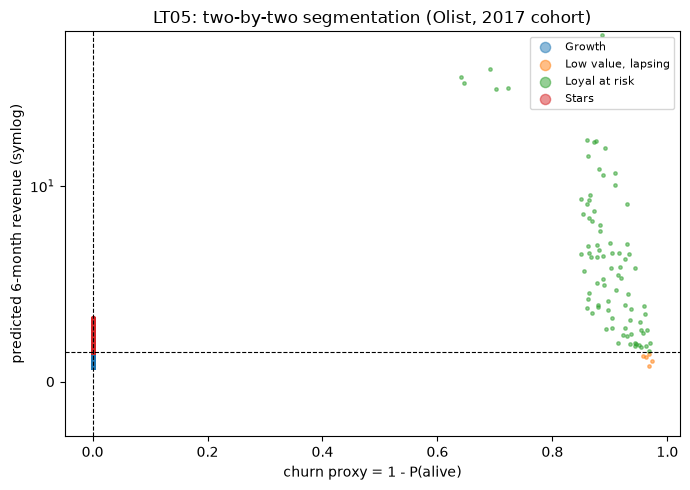

In [6]:
sample = seg.sample(min(5000, len(seg)), random_state=42)
fig, ax = plt.subplots(figsize=(7, 5))
for name, g in sample.groupby("segment"):
    ax.scatter(g["churn_proxy"], g["pred_clv"], s=6, alpha=0.5, label=name)
ax.axhline(seg.attrs["clv_median"], color="k", lw=0.8, ls="--")
ax.axvline(seg.attrs["churn_median"], color="k", lw=0.8, ls="--")
ax.set_yscale("symlog", linthresh=10)
ax.set_xlabel("churn proxy = 1 - P(alive)")
ax.set_ylabel("predicted 6-month revenue (symlog)")
ax.legend(markerscale=3, fontsize=8)
ax.set_title("LT05: two-by-two segmentation (Olist, 2017 cohort)")
fig.tight_layout()
fig.savefig(FIGS / "lt05_segment_grid.png", dpi=120)
plt.show()

## 6. Save the reports

No customer-level rows are written. Only aggregates are saved.

In [7]:
profile.to_csv(REPORTS / "lt05_segment_profile.csv", index=False)
summary = {
    "obs_window": [str(w.obs_start.date()), str(w.obs_end.date())],
    "holdout_window": [str(w.obs_end.date()), str(w.hold_end.date())],
    "customers_scored": int(len(seg)),
    "clv_median": seg.attrs["clv_median"],
    "churn_median": seg.attrs["churn_median"],
    "spearman_pred_clv_vs_holdout_revenue": float(rho),
    "auc_p_alive_vs_bought_in_holdout": float(auc_alive),
    "share_bought_in_holdout": float(bought.mean()),
    "share_repeat_buyers": share_repeat,
    "auc_p_alive_repeat_buyers": float(auc_alive_repeat),
    "share_p_alive_equal_one": float((seg["p_alive"] >= 1.0).mean()),
}
(REPORTS / "lt05_summary.json").write_text(json.dumps(summary, indent=2))
summary

{'obs_window': ['2017-01-01', '2018-01-01'],
 'holdout_window': ['2018-01-01', '2018-07-01'],
 'customers_scored': 42136,
 'clv_median': 1.509267887791503,
 'churn_median': 0.0,
 'spearman_pred_clv_vs_holdout_revenue': 0.021759957851758945,
 'auc_p_alive_vs_bought_in_holdout': 0.46921577317039287,
 'share_bought_in_holdout': 0.01276817922916271,
 'share_repeat_buyers': 0.016850199354471237,
 'auc_p_alive_repeat_buyers': 0.6754883090960936,
 'share_p_alive_equal_one': 0.9831498006455288}